In [ ]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [ ]:
from sklearn.datasets import load_iris
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['Species'] = iris.target

In [ ]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [ ]:
df = df.iloc[:,1:]

In [ ]:
df.head()

,sepal width (cm),petal length (cm),petal width (cm),Species
0,3.5,1.4,0.2,0
1,3.0,1.4,0.2,0
2,3.2,1.3,0.2,0
3,3.1,1.5,0.2,0
4,3.6,1.4,0.2,0


In [ ]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()


In [ ]:
df['Species'] = encoder.fit_transform(df['Species'])

In [ ]:
df.head()

,sepal width (cm),petal length (cm),petal width (cm),Species
0,3.5,1.4,0.2,0
1,3.0,1.4,0.2,0
2,3.2,1.3,0.2,0
3,3.1,1.5,0.2,0
4,3.6,1.4,0.2,0


In [ ]:
df = df[df['Species'] != 0][['sepal width (cm)', 'petal length (cm)', 'Species']]

In [ ]:
df.head()

,sepal width (cm),petal length (cm),Species
50,3.2,4.7,1
51,3.2,4.5,1
52,3.1,4.9,1
53,2.3,4.0,1
54,2.8,4.6,1


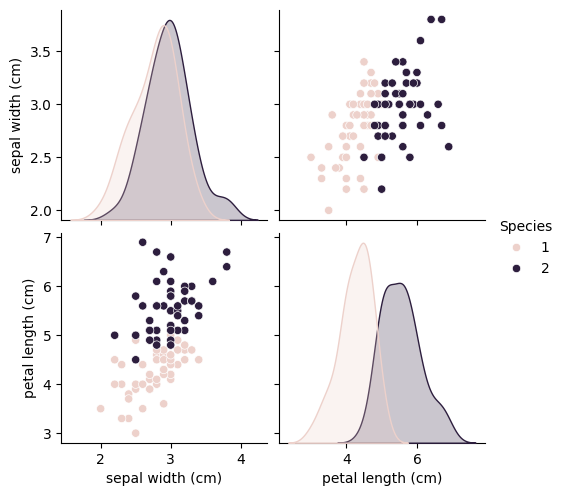

In [ ]:
import seaborn as sns
sns.pairplot(df, hue='Species')

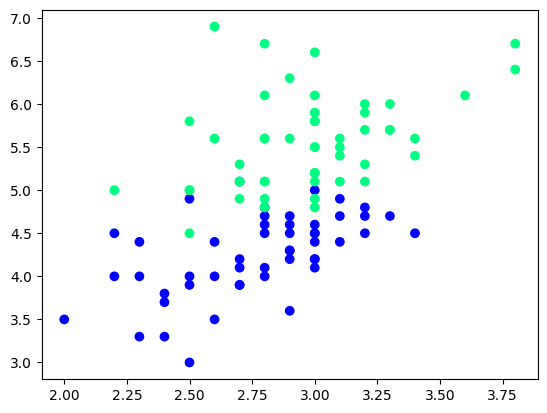

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(df['sepal width (cm)'], df['petal length (cm)'], c=df['Species'], cmap='winter')

In [ ]:
df_train = df.iloc[:60,:].sample(10)
df_train


,sepal width (cm),petal length (cm),Species
72,2.5,4.9,1
102,3.0,5.9,2
85,3.4,4.5,1
67,2.7,4.1,1
94,2.7,4.2,1
52,3.1,4.9,1
77,3.0,5.0,1
106,2.5,4.5,2
64,2.9,3.6,1
76,2.8,4.8,1


In [ ]:
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10)
df_val = df.iloc[60:80,:].sample(5)
df_test = df.iloc[80:,:].sample(5)

In [ ]:
df_train

,sepal width (cm),petal length (cm),Species
109,3.6,6.1,2
67,2.7,4.1,1
78,2.9,4.5,1
126,2.8,4.8,2
75,3.0,4.4,1
51,3.2,4.5,1
125,3.2,6.0,2
87,2.3,4.4,1
88,3.0,4.1,1
70,3.2,4.8,1


In [ ]:
df_val

,sepal width (cm),petal length (cm),Species
134,2.6,5.6,2
52,3.1,4.9,1
148,3.4,5.4,2
135,3.0,6.1,2
121,2.8,4.9,2


In [ ]:
df_test

,sepal width (cm),petal length (cm),Species
69,2.5,3.9,1
74,2.9,4.3,1
92,2.6,4.0,1
85,3.4,4.5,1
95,3.0,4.2,1


In [ ]:
X_test = df_test.iloc[:, 0:2].values

In [ ]:
y_test = df_test.iloc[:,-1].values

In [ ]:
y_test

array([1, 1, 1, 1, 1])

In [ ]:
# Case 1: Bagging

In [ ]:
df_bag = df_train.sample(8,replace=True)

X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

df_bag

,sepal width (cm),petal length (cm),Species
75,3.0,4.4,1
70,3.2,4.8,1
87,2.3,4.4,1
78,2.9,4.5,1
67,2.7,4.1,1
51,3.2,4.5,1
126,2.8,4.8,2
109,3.6,6.1,2


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score


In [ ]:
dt_bag1 = DecisionTreeClassifier()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


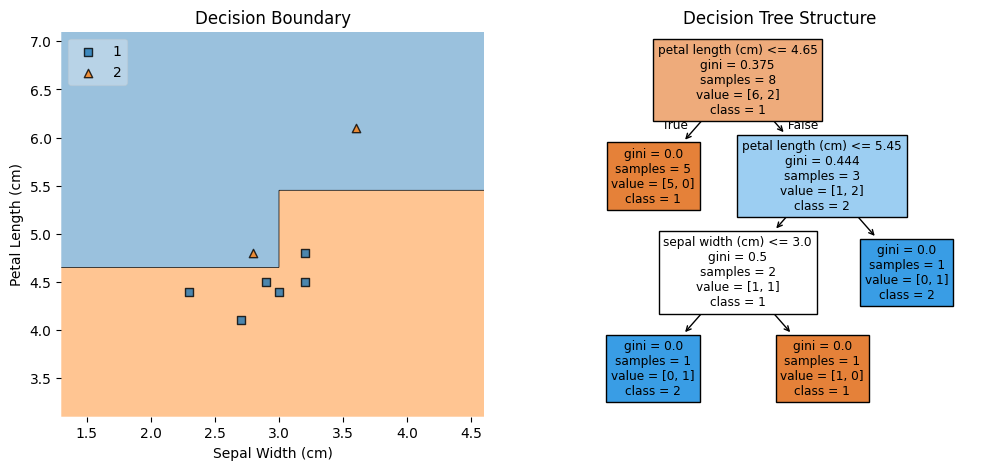

Training Accuracy: 100.00%


In [ ]:
def evaluate(clf, X, y):
    # Fit the classifier
    clf.fit(X, y)

    # Plot Decision Regions
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    plt.xlabel('Sepal Width (cm)')
    plt.ylabel('Petal Length (cm)')
    plt.title('Decision Boundary')

    # Plot Decision Tree Structure
    plt.subplot(1, 2, 2)
    plot_tree(clf, feature_names=X.columns, class_names=['1', '2'], filled=True)
    plt.title('Decision Tree Structure')
    plt.show()

    # Print accuracy
    y_pred = clf.predict(X)
    print(f"Training Accuracy: {accuracy_score(y, y_pred) * 100:.2f}%")

evaluate(dt_bag1, X, y)

In [ ]:
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,sepal width (cm),petal length (cm),Species
126,2.8,4.8,2
78,2.9,4.5,1
70,3.2,4.8,1
51,3.2,4.5,1
125,3.2,6.0,2
88,3.0,4.1,1
51,3.2,4.5,1
51,3.2,4.5,1


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


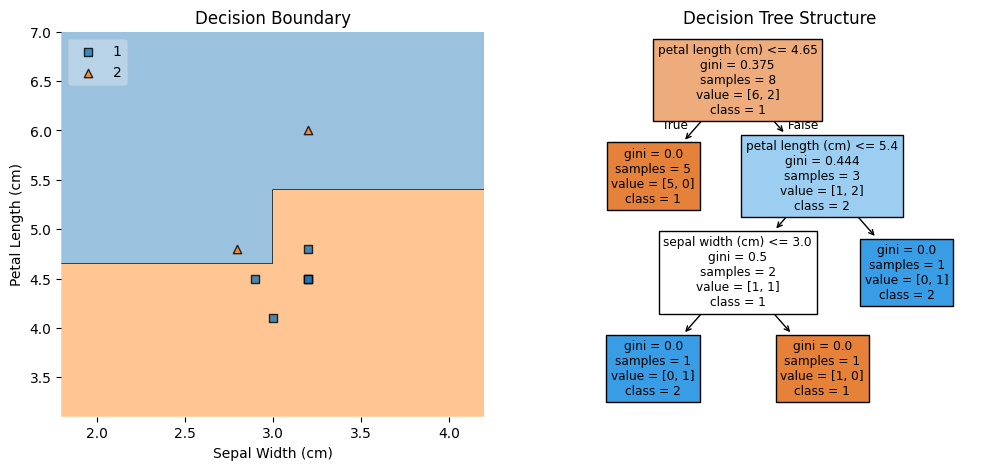

Training Accuracy: 100.00%


In [ ]:
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2,X,y)


In [ ]:
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag


,sepal width (cm),petal length (cm),Species
51,3.2,4.5,1
51,3.2,4.5,1
75,3.0,4.4,1
126,2.8,4.8,2
126,2.8,4.8,2
67,2.7,4.1,1
125,3.2,6.0,2
75,3.0,4.4,1


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


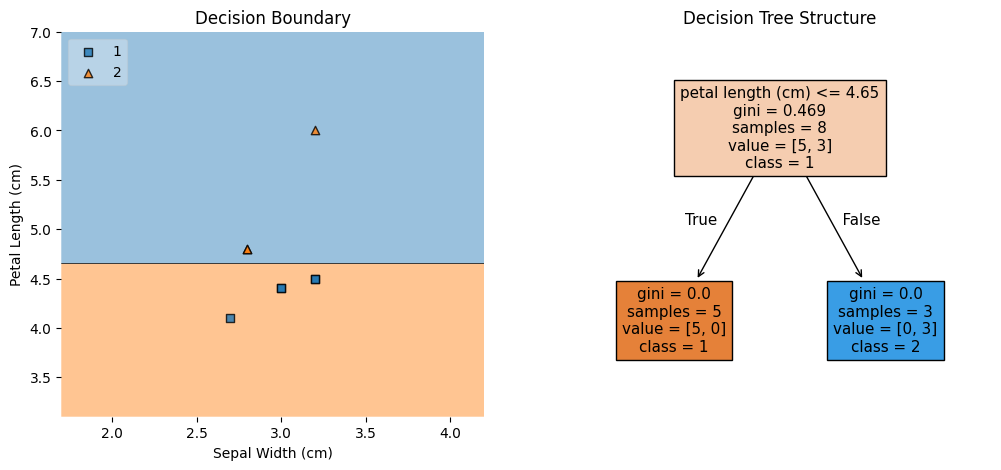

Training Accuracy: 100.00%


In [ ]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

In [ ]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))


In [47]:
df_test

,sepal width (cm),petal length (cm),Species
69,2.5,3.9,1
74,2.9,4.3,1
92,2.6,4.0,1
85,3.4,4.5,1
95,3.0,4.2,1


In [48]:
print("Predictor 1",dt_bag1.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.2,5.0]).reshape(1,2)))

Predictor 1 [2]
Predictor 2 [2]
Predictor 3 [2]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


In [ ]:
#Pasting


In [49]:
df_train

,sepal width (cm),petal length (cm),Species
109,3.6,6.1,2
67,2.7,4.1,1
78,2.9,4.5,1
126,2.8,4.8,2
75,3.0,4.4,1
51,3.2,4.5,1
125,3.2,6.0,2
87,2.3,4.4,1
88,3.0,4.1,1
70,3.2,4.8,1


In [50]:
df_train.sample(8)

,sepal width (cm),petal length (cm),Species
67,2.7,4.1,1
109,3.6,6.1,2
78,2.9,4.5,1
70,3.2,4.8,1
88,3.0,4.1,1
125,3.2,6.0,2
51,3.2,4.5,1
126,2.8,4.8,2


In [52]:
df1 = df.sample(10)
df1

,sepal width (cm),petal length (cm),Species
137,3.1,5.5,2
136,3.4,5.6,2
144,3.3,5.7,2
124,3.3,5.7,2
77,3.0,5.0,1
102,3.0,5.9,2
149,3.0,5.1,2
120,3.2,5.7,2
105,3.0,6.6,2
125,3.2,6.0,2


In [53]:
df1.sample(2,replace=True,axis=1)

,sepal width (cm),petal length (cm)
137,3.1,5.5
136,3.4,5.6
144,3.3,5.7
124,3.3,5.7
77,3.0,5.0
102,3.0,5.9
149,3.0,5.1
120,3.2,5.7
105,3.0,6.6
125,3.2,6.0


In [54]:
#Random patches

In [55]:
df1

,sepal width (cm),petal length (cm),Species
137,3.1,5.5,2
136,3.4,5.6,2
144,3.3,5.7,2
124,3.3,5.7,2
77,3.0,5.0,1
102,3.0,5.9,2
149,3.0,5.1,2
120,3.2,5.7,2
105,3.0,6.6,2
125,3.2,6.0,2


In [56]:
df1.sample(8,replace=True).sample(2,replace=True,axis=1)

,petal length (cm),Species
77,5.0,1
124,5.7,2
77,5.0,1
105,6.6,2
120,5.7,2
105,6.6,2
124,5.7,2
120,5.7,2
